# Question 2: Vision in the Real World – Indian Currency Classification

**Estimated Time:** 8 Hours  
**Total:** 75 Points  
**Objective:** Apply CNNs to a culturally relevant, noisy dataset. Learn to reason about spatial dimensions, design parameter-efficient architectures, and interpret model decisions.

**Dataset:** “Indian Currency Notes” (denominations INR 10 – INR 2000). Create your own dataset, upload it to Google Drive, and share the link in submission. Resize all images to **128×128**.

> If unavailable, you may substitute **Oxford Flowers-102** (via `torchvision`) and mention it clearly in your submission.

## Part A: Theoretical Foundations [25 Points]

### 2A.1 Spatial Dimension Calculation [5 pts]
The output spatial dimension for a convolutional layer is:

$$
O = \left\lfloor \frac{I - K + 2P}{S} \right\rfloor + 1
$$

**(a)** Calculate output volume (**channels × height × width**) when a $3\times128\times128$ image passes through Conv2D with 32 filters, kernel $3\times3$, stride 2, padding 1.  
**(b)** Pass that output through another Conv2D with 64 filters, kernel $3\times3$, stride 1, padding 1. Give resulting volume.

(a) For the first Conv2D layer:
- Input dimensions: \( I = 128 \) (height and width), \( C_{in} = 3 \) (channels)
- Kernel size: \( K = 3 \times 3 \)
- Stride: \( S = 2 \)
- Padding: \( P = 1 \)
Calculating output height and width:
$$O = \left\lfloor \frac{128 - 3 + 2 \cdot 1}{2} \right\rfloor + 1 = \left\lfloor \frac{128 - 3 + 2}{2} \right\rfloor + 1 = \left\lfloor \frac{127}{2} \right\rfloor + 1 = 63 + 1 = 64$$
Output channels: \( C_{out} = 32 \)
Output volume: \( 32 \times 64 \times 64 \) 

(b) For the second Conv2D layer:
- Input dimensions: \( I = 64 \) (height and width), \( C_{in} = 32 \) (channels)
- Kernel size: \( K = 3 \times 3 \)
- Stride: \( S = 1 \)
- Padding: \( P = 1 \)
Calculating output height and width:
$$O = \left\lfloor \frac{64 - 3 + 2 \cdot 1}{1} \right\rfloor + 1 = \left\lfloor \frac{64 - 3 + 2}{1} \right\rfloor + 1 = \left\lfloor \frac{63}{1} \right\rfloor + 1 = 63 + 1 = 64$$
Output channels: \( C_{out} = 64 \)
Output volume: \( 64 \times 64 \times 64 \)

### 2A.2 Receptive Field [5 pts]

**(a)** Define receptive field of a convolutional neuron. Why should it cover a large part of the input image?  

**(b)** Compute receptive field at output of two stacked \(3\times3\) convolutions (stride 1, no pooling). Compare with one \(5\times5\) convolution and state which uses fewer parameters.

(a)
Receptive Field (RF) is defined as the size of the region in the input that produces the feature. Basically, it is a measure of association of an output feature (of any layer) to the input region (patch). a small receptive field may not be able to recognize large objects. large receptive fields are necessary for high-level recognition tasks. 

(b)
$$RF_l = RF_{l-1} + (k_l - 1) \times \prod_{i=1}^{l-1} s_i$$
where $k_l$ is the kernel size and $s_i$ is the stride at layer $i$. initial receptive field $RF_0 = 1$.
For two stacked \(3\times3\) convolutions:
- After first convolution:
$$RF_1 = RF_0 + (3 - 1) \times 1 = 1 + 2 = 3$$
- After second convolution:
$$RF_2 = RF_1 + (3 - 1) \times 1 = 3 + 2 = 5$$
So, the receptive field after two stacked \(3\times3\) convolutions is 5.


For one \(5\times5\) convolution:
$$RF = RF_0 + (5 - 1) \times 1 = 1 + 4 = 5$$
So, the receptive field for one \(5 \times 5\) convolution is 5.

### 2A.3 Parameter Efficiency [8 pts]

**(a)** Compute learnable parameters (weights + biases) for standard Conv2D mapping 32 input channels to 64 output channels with \(3\times3\) kernel.  

**(b)** Compute parameters for depthwise separable version: \(3 \times 3\) depthwise conv + \(1\times1\) pointwise conv (include biases).  

**(c)** Compute compression ratio and explain why MobileNet-style architectures use this factorization heavily.

## (a) Standard Conv2D


$$\text{weights} = 64 \times 32 \times 3 \times 3 = 18{,}432$$
$$\text{biases} = 64$$
$$\boxed{\text{total} = 18{,}496}$$

---

## (b) Depthwise Separable

**Depthwise conv** — one 3×3 filter per input channel, no cross-channel mixing:

$$\text{weights} = 32 \times 3 \times 3 = 288, \quad \text{biases} = 32$$

**Pointwise conv** — 1×1 conv combining all 32 channels into 64 outputs:

$$\text{weights} = 64 \times 32 \times 1 \times 1 = 2{,}048, \quad \text{biases} = 64$$

$$\boxed{\text{total} = 288 + 32 + 2{,}048 + 64 = 2{,}432}$$

---

## (c) Compression ratio

$$\text{ratio} = \frac{18{,}496}{2{,}432} \approx 7.6\times \text{ fewer parameters}$$

Depthwise separable factorizes them into two cheap sequential steps: spatial filtering costs only Cin×K2C_{in} \times K^2
Cin​×K2, then channel mixing costs Cin×CoutC_{in} \times C_{out}
Cin​×Cout​. The savings are multiplicative, so they compound across every layer in the network — making the total model ~8–9× smaller and faster,  which is needed to run inference on a mobile CPU in real time.



### 2A.4 BatchNorm vs. LayerNorm – Choosing the Right Normalization [7 pts]

**(a) BatchNorm axis (2 pts).** For feature map shape \((B,C,H,W)\), over which axes are mean/variance computed in BatchNorm?  

**(b) Small-batch failure mode (2 pts).** With batch size 2, why are BatchNorm statistics unreliable? Name one robust alternative (other than LayerNorm).
  
**(c) Why not BatchNorm in Transformers? (3 pts).** Explain why batch-level sequence statistics are problematic with padded variable-length sequences and why LayerNorm is preferred.

**(a)** BatchNorm computes mean and variance over the axes corresponding to the batch and spatial dimensions, i.e., over axes 0 (batch), 2 (height), and 3 (width). The normalization is done per channel, so the statistics are computed for each channel independently.

**(b)** With a batch size of 2, the mean and variance estimates for BatchNorm are highly unreliable because they are based on only two samples. This can lead to noisy updates and poor convergence during training. One robust alternative is **Group Normalization**, which divides channels into groups and computes statistics within each group, making it less sensitive to batch size.

**(c)** In Transformers, input sequences often have variable lengths and are padded to a common length for batch processing. BatchNorm relies on batch-level statistics, which can be skewed by the presence of padding tokens that do not represent meaningful data. This can lead to incorrect normalization and hinder model performance. LayerNorm, on the other hand, normalizes across the feature dimension for each individual token, making it unaffected by padding and thus more suitable for sequence data in Transformers.

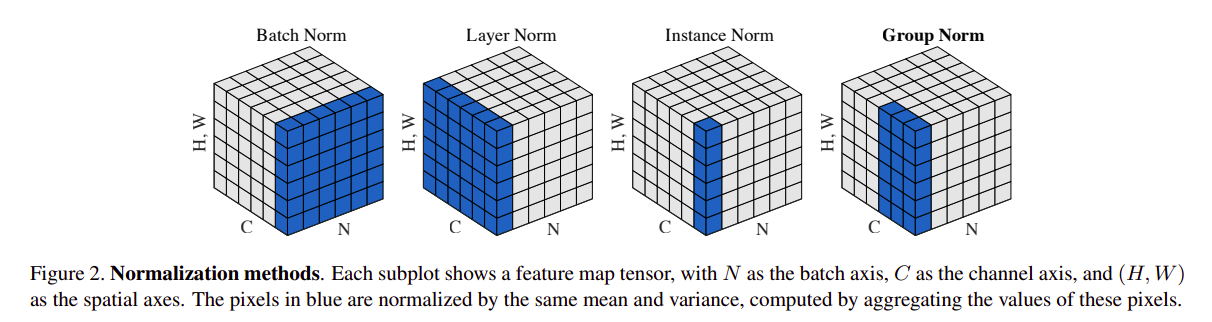

## Part B: Practical Implementation [50 Points]

### 2B.1 Baseline CNN [10 pts]
Design 4 conv blocks, each: `Conv2D → BatchNorm → ReLU → MaxPool(2)`.
Then use `Global Average Pooling → Linear`.
Train for 15 epochs and report training loss + test accuracy.

In [18]:
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image

In [19]:
train_dataset = datasets.ImageFolder(root='dataset/train-dataset', transform=transforms.Compose([transforms.ToTensor(), transforms.Resize((128,128))]))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=8, pin_memory=True)
test_dataset = datasets.ImageFolder(root='dataset/test-dataset', transform=transforms.Compose([transforms.ToTensor(), transforms.Resize((128,128))]))
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=8, pin_memory=True)

In [20]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [21]:
train_dataset[0]

(tensor([[[0.9294, 0.9294, 0.9302,  ..., 0.9333, 0.9296, 0.9272],
          [0.9494, 0.9484, 0.9415,  ..., 0.9389, 0.9407, 0.9447],
          [0.9497, 0.9486, 0.9429,  ..., 0.9423, 0.9413, 0.9408],
          ...,
          [0.9505, 0.9442, 0.9416,  ..., 0.9511, 0.9589, 0.9601],
          [0.9457, 0.9418, 0.9388,  ..., 0.9491, 0.9529, 0.9513],
          [0.9440, 0.9515, 0.9450,  ..., 0.9479, 0.9497, 0.9531]],
 
         [[0.9098, 0.9098, 0.9106,  ..., 0.9110, 0.9100, 0.9076],
          [0.9298, 0.9288, 0.9219,  ..., 0.9167, 0.9211, 0.9251],
          [0.9301, 0.9290, 0.9233,  ..., 0.9203, 0.9217, 0.9212],
          ...,
          [0.9309, 0.9246, 0.9220,  ..., 0.9300, 0.9393, 0.9405],
          [0.9261, 0.9222, 0.9192,  ..., 0.9283, 0.9333, 0.9317],
          [0.9243, 0.9318, 0.9254,  ..., 0.9302, 0.9301, 0.9335]],
 
         [[0.8981, 0.8981, 0.8988,  ..., 0.9002, 0.8983, 0.8959],
          [0.9180, 0.9171, 0.9101,  ..., 0.9059, 0.9094, 0.9133],
          [0.9183, 0.9172, 0.9115,  ...,

In [22]:
img, label = train_dataset[0]
print(f"Image shape: {img.size}, Label: {label}")

Image shape: <built-in method size of Tensor object at 0x72fd21b12440>, Label: 0


In [23]:
train_dataset.classes

['1', '10', '100', '2', '20', '200', '2000', '5', '50', '500']

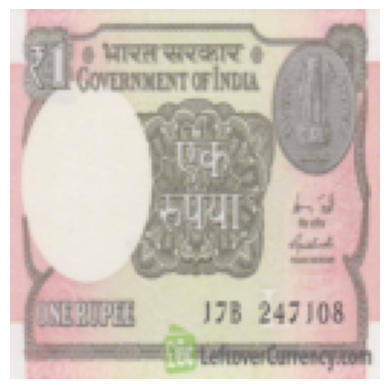

In [24]:
img = img.permute(1, 2, 0) # Convert from (C, H, W) to (H, W, C) for visualization
plt.imshow(img)
plt.axis('off')
plt.show()

In [25]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
    
    def forward(self, x):
        return self.block(x)
    

class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        
        self.layer1 = ConvBlock(3, 32)
        self.layer2 = ConvBlock(32, 64)
        self.layer3 = ConvBlock(64, 128)
        self.layer4 = ConvBlock(128, 256)
        
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) 
        self.fc = nn.Linear(256, num_classes)
    
    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.gap(x)        # (B, 256, 1, 1)
        x = x.view(x.size(0), -1)  # flatten → (B, 256)
        x = self.fc(x)
        
        return x

In [26]:
len(train_dataset.classes)

10

In [27]:
model = CNN(num_classes=len(train_dataset.classes))
model.to(device)

CNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): ConvBlock(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (l

In [28]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # Move to GPU if available
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/15], Loss: 1.6501


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [2/15], Loss: 1.2817


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [3/15], Loss: 1.0276


... (20 outputs left out)

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [14/15], Loss: 0.2304


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [15/15], Loss: 0.2140


In [30]:
correct = 0
total = 0
model.eval()
for img, label in test_dataset:
    img = img.unsqueeze(0).to(device)  
    output = model(img)
    predicted_label = torch.argmax(output, dim=1).item()
    if predicted_label == label:
        correct += 1
    total += 1

    # print(f"True Label: {label}, Predicted Label: {predicted_label}")

print(f"Accuracy: {correct/total*100:.2f}%")

Accuracy: 46.92%


### 2B.2 Mobile-Friendly CNN [12 pts]
Replace the last two conv blocks with depthwise separable convolutions and train for 15 epochs.

**(a)** Print parameter count of both models using `sum(p.numel() for p in model.parameters())`.  
**(b)** Report test accuracy for both and check whether mobile-friendly model is comparable.  
**(c)** Compute actual compression ratio and compare with theoretical value from 2A.3.

In [32]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_channels, in_channels,
            kernel_size=3, padding=1,
            groups=in_channels,   
            bias=False           
        )

        self.pointwise = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=1,
            bias=False
        )

        self.bn  = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU()

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn(x)
        x = self.act(x)
        return x

In [33]:
class DSConvBlock(nn.Module):
    """Depthwise separable conv block — used for layer3 and layer4."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            DepthwiseSeparableConv(in_channels, out_channels),
            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):
        return self.block(x)

class MobileFriendlyCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.layer1 = ConvBlock(3,   32)   
        self.layer2 = ConvBlock(32,  64)   
        self.layer3 = DSConvBlock(64,  128) 
        self.layer4 = DSConvBlock(128, 256)  

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc  = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x



In [34]:
model = MobileFriendlyCNN(num_classes=len(train_dataset.classes))

In [35]:
model.to(device)

MobileFriendlyCNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): DSConvBlock(
    (block): Sequential(
      (0): DepthwiseSeparableConv(
        (depthwise): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (pointwise): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, m

In [36]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/15], Loss: 1.6677


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [2/15], Loss: 1.2927


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [3/15], Loss: 1.0399


... (20 outputs left out)

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [14/15], Loss: 0.2049


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [15/15], Loss: 0.2083


In [37]:
correct = 0
total = 0
model.eval()
for img, label in test_dataset:
    img = img.unsqueeze(0).to(device)  
    output = model(img)
    predicted_label = torch.argmax(output, dim=1).item()
    if predicted_label == label:
        correct += 1
    total += 1

    # print(f"True Label: {label}, Predicted Label: {predicted_label}")

print(f"Accuracy: {correct/total*100:.2f}%")

Accuracy: 36.15%


### 2B.3 Data Augmentation Study [10 pts]
Train mobile-friendly model with:
- `RandomRotation(±30°)`
- `ColorJitter(brightness=0.3, contrast=0.3)`
- `RandomHorizontalFlip(p=0.5)`
- `RandomAffine(degrees=0, translate=(0.1, 0.1))`

Report test accuracy change vs no augmentation.

**Thought:** Should augmentation be applied to test set? Justify in 2–3 sentences.

In [48]:
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import ConcatDataset

base_transform = T.Compose([
    T.ToTensor(),
    T.Resize((128, 128))
])

aug_transform = T.Compose([
    T.RandomRotation(30),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.ToTensor(),
    T.Resize((128, 128))
])

dataset_original = ImageFolder(root='dataset/train-dataset', transform=base_transform)
dataset_augmented = ImageFolder(root='dataset/train-dataset', transform=aug_transform)

final_dataset = ConcatDataset([dataset_original, dataset_augmented])
final_loader = DataLoader(final_dataset, batch_size=32, shuffle=True, num_workers=8, pin_memory=True)

In [49]:
model = MobileFriendlyCNN(num_classes=len(train_dataset.classes))
model.to(device)

MobileFriendlyCNN(
  (layer1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (layer3): DSConvBlock(
    (block): Sequential(
      (0): DepthwiseSeparableConv(
        (depthwise): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (pointwise): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=1e-05, m

In [50]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 15 

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    
    for images, labels in final_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(final_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/15], Loss: 1.5762


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [2/15], Loss: 1.1296


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [3/15], Loss: 0.8779


... (20 outputs left out)

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [14/15], Loss: 0.2535


/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/miniconda3/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/home/vanshnawander/

Epoch [15/15], Loss: 0.2539


In [ ]:
correct = 0
total = 0
model.eval()
predicted_labels = []
for img, label in test_dataset:
    img = img.unsqueeze(0).to(device)  
    output = model(img)
    predicted_label = torch.argmax(output, dim=1).item()
    if predicted_label == label:
        correct += 1
        # print(total)
    total += 1
    predicted_labels.append(predicted_label)

    # print(f"True Label: {label}, Predicted Label: {predicted_label}")

print(f"Accuracy: {correct/total*100:.2f}%")

14
19
22
23
24
31
32
33
34
35
36
37
38
39
40
41
42
43
44
46
64
65
66
67
70
71
72
73
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
108
109
110
112
113
114
115
116
117
118
121
124
125
Accuracy: 47.69%


In [77]:
predicted_labels

[9,
 9,
 9,
 1,
 1,
 6,
 9,
 1,
 9,
 9,
 9,
 9,
 9,
 9,
 0,
 2,
 2,
 2,
 6,
 0,
 9,
 9,
 1,
 1,
 1,
 9,
 9,
 9,
 9,
 9,
 9,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 6,
 6,
 6,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 1,
 5,
 5,
 5,
 5,
 1,
 1,
 5,
 5,
 5,
 5,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 6,
 9,
 9,
 9,
 9,
 9,
 8,
 8,
 8,
 1,
 9,
 9,
 9,
 9,
 9,
 9,
 9,
 1,
 1,
 9,
 1,
 1,
 9,
 9,
 1,
 1,
 1,
 1]

### 2B.4 Interpretability with Grad-CAM [10 pts]
Using `pytorch-grad-cam`:

**(a)** Generate Grad-CAM heatmaps for final conv layer of baseline model.  
**(b)** Choose one correctly classified image from three denominations (e.g., INR 500, 200, 2000) and overlay heatmaps on originals.  
**(c)** Analyze in 3–4 sentences what model attends to (numeral, portrait, color, motif) and whether behavior is consistent.

In [55]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import cv2
import numpy as np

In [84]:
image, label = test_dataset[31]
input_tensor = image.unsqueeze(0) 

In [85]:
output = model(input_tensor.to(device))
predicted_label = torch.argmax(output, dim=1).item()
predicted_label

1

In [86]:
label

1

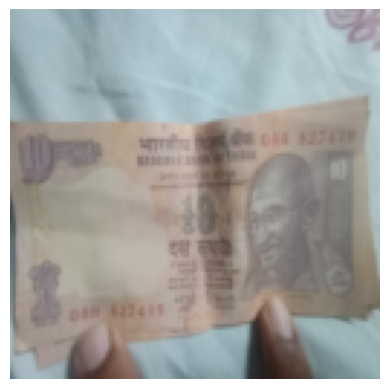

In [87]:
img = image.permute(1, 2, 0) # Convert from (C, H, W) to (H, W, C) for visualization
plt.imshow(img)
plt.axis('off')
plt.show()

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

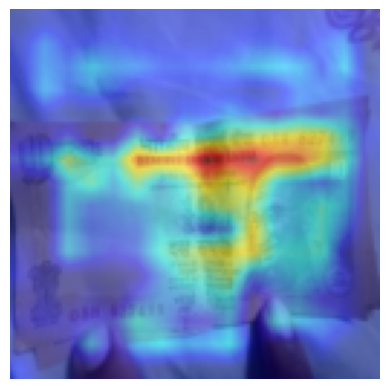

In [88]:
cam = GradCAM(model=model, target_layers=[model.layer4.block[0]])

grayscale_cam = cam(input_tensor=input_tensor)

image = input_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

visualization = show_cam_on_image(image, grayscale_cam[0], use_rgb=True)

plt.imshow(visualization)
plt.axis('off')

### 2B.5 Confusion Matrix Analysis [8 pts]

**(a)** Compute and display confusion matrix for best model on test set using `sklearn.metrics.confusion_matrix` and `seaborn.heatmap`.  
**(b)** Identify two most confused denomination pairs and hypothesize why (color, size, shared visual cues).  
**(c)** Propose one targeted strategy (beyond generic augmentation) to reduce this confusion.

## AI Attribution
- It helped me a lot in formatting this to a proper format espically the markdown cells latex part.
- I used it in the implementation of depthwise convolution and composing transforms for data augmentation.
- It also taught me Grad cam which i was able to use later in the implementation.